# **CLASIFICACIÓN DE FRAGMENTOS BHC CON GPT-2**
## **Tarea Sequence-Clasification**

El objetivo es clasificar fragmentos de notas de alta en dos categorías: **BHC** y **no BHC** (*Brief Hospital Course*).
Se utiliza GPT-2 y se ajustan sus pesos con los fragmentos preparados a partir de la base de datos. La base de datos a utilizar es MIMIC-IV-NOTES, esta base de datos contiene los resumenes de alta de los pacientes y las notas de radiología, para este caso se utiliza la seccón de resumenes de alta, de la cual **BHC** hace parte.

# **INSTALACIONES E IMPORTACIONES**


In [ ]:
!pip install -q transformers
!pip install -q datasets
!pip install -q accelerate

In [ ]:
from google.colab import drive, auth
from google.cloud import bigquery
from pathlib import Path

import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import json
import re
import gc

from itertools import product
from inspect import signature
from hashlib import sha256
from tempfile import TemporaryDirectory
from time import perf_counter

import transformers

from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
    confusion_matrix,
    classification_report,
)
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    GPT2ForSequenceClassification,
    PreTrainedTokenizerBase,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EvalPrediction,
    set_seed,
)

from collections import Counter
import string


# **CONSTANTES**

In [ ]:
PROJECT_ID = "physionet-506416"
PROJECT = "physionet-data"
DATASET_H = "mimiciv_3_1_hosp"
DATASET_N = "mimiciv_note"
TABLE = "admissions"

DRIVE_ROUTE = "/content/drive"
NOTES_ROUTE = "/content/drive/MyDrive/MIMIC/physionet.org/files/mimic-iv-note/2.2"
OUTPUT_ROUTE = "/content/drive/MyDrive/MIMIC/Clasificacion_Tarea"
MANUAL_REVIEW_ROUTE = ""
MODEL_ID = "openai-community/gpt2"
PAD_TOKEN = "[BHC_PAD]"

SEED = 42
N_ADMISSIONS = 300
CSV_CHUNK_SIZE = 2000
HOLDOUT_SIZE = 0.30
TEST_SIZE_IN_HOLDOUT = 0.50
MIN_BHC_CHARS = 100
MAX_LENGTH = 256
MAX_FRAGMENT_TOKENS = 240

LEARNING_RATES = [0.0001, 0.001, 0.01]
WEIGHT_DECAYS = [0.001, 0.01, 0.1]
TRAIN_EPOCHS = [1, 3]
BATCH_SIZES = [4, 16]
WARMUP_RATIOS = [0.03, 0.1]

NUM_TRAIN_EPOCHS = 2
BATCH_SIZE = 8
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
SEARCH_TEMP_ROUTE = "/content/gpt2_bhc_grid"

N_SEARCH_ADMISSIONS = 80
INFERENCE_BATCH_SIZE = 16
OPTIMIZER = "adamw_torch"
LR_SCHEDULER_TYPE = "linear"
MAX_GRAD_NORM = 1.0
LOGGING_STEPS = 25
THRESHOLDS = np.linspace(0.10, 0.90, 17)
MIN_POSITIVE_FRAGMENTS = 2

ID_TO_LABEL = {0: "NO_BHC", 1: "BHC"}
LABEL_TO_ID = {"NO_BHC": 0, "BHC": 1}
VALID_ANNOTATIONS = ("rule_valid", "manual_valid")
BHC_HEADERS = ("brief hospital course", "hospital course")
MAIN_HEADERS = (
    "name", "patient name", "unit no", "unit number", "admission date", "discharge date",
    "date of birth", "sex", "gender", "service", "allergies", "allergy", "attending",
    "attending physician", "chief complaint", "major surgical or invasive procedure",
    "major surgical or invasive procedures", "history of present illness",
    "past medical history", "social history", "family history", "physical exam",
    "physical examination", "pertinent results", "brief hospital course", "hospital course",
    "medications on admission", "admission medications", "discharge medications",
    "medications at discharge", "discharge disposition", "discharge diagnosis",
    "discharge diagnoses", "discharge condition", "condition at discharge",
    "discharge instructions", "followup instructions", "follow-up instructions",
    "follow up instructions", "addendum",
)
HEADER_ALTERNATIVES = "|".join(
    re.escape(title).replace(r"\ ", r"[ \t]+")
    for title in sorted(MAIN_HEADERS, key = len, reverse = True)
)
HEADER_PATTERN = re.compile(
    rf"(?:^[ \t]*|[ \t]{{2,}})(?P<title>{HEADER_ALTERNATIVES})\.?[ \t]*:",
    re.IGNORECASE | re.MULTILINE,
)
HEADER_ALONE_PATTERN = re.compile(
    rf"^[ \t]*(?P<title>{HEADER_ALTERNATIVES})\.?[ \t]*\r?$",
    re.IGNORECASE | re.MULTILINE,
)


# **CONFIGURACIONES**


In [ ]:
drive.mount(DRIVE_ROUTE)
auth.authenticate_user()

client = bigquery.Client(project = PROJECT_ID)
random = np.random.default_rng(seed = SEED)
set_seed(SEED)

output_path = Path(OUTPUT_ROUTE)
output_path.mkdir(parents = True, exist_ok = True)
model_path = output_path / "modelo"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Mounted at /content/drive


# **BASE DE DATOS Y OBJETIVO**

La fuente es MIMIC-IV-Note, versión 2.2. Contiene notas de alta desidentificadas en inglés. Se conserva la vinculación con
las admisiones del módulo Hospital de MIMIC-IV a través de las columnas de hadm_id, cada hadm_id posee un único _discharge summary_.

El objetivo del clasificador es identificar qué fragmentos de una nota pertenecen a *Brief Hospital Course* (BHC). La unidad de entrada del modelo será una línea de texto o una parte de una línea larga, esta linea puede ser cualquier parte del *Discharge Summary*, por lo que podrá ser clasificado como BHC o no BHC. La salida será una etiqueta binaria 1 y 0, que definiran que es o no es BHC.

Las etiquetas se construyen localizando el encabezado BHC y el siguiente encabezado principal. Son etiquetas automáticas. La clase depende de la sección donde aparece el fragmento, no de que mencione un tratamiento o diagnóstico. Los identificadores y la etiqueta no se entregan como texto al modelo para evitar data leakage.

El clasificador permite identificar que fragmentos pertenecen al BHC dentro de las notas de alta, separandolos del resto del documento. Esto puede ser especialmente util en casos donde las expresiones regulares (re) no pueden extraer reconociblemente el BHC de las notas de alta o donde la extracción es ambigua.

# LECTURA DE DATOS


In [ ]:
query_notes = f"""
SELECT DISTINCT hadm_id
FROM `{PROJECT}.{DATASET_N}.discharge`
WHERE hadm_id IS NOT NULL
"""
note_ids = client.query(query_notes).to_dataframe(create_bqstorage_client = False)["hadm_id"].to_numpy(dtype = np.int64)
note_ids = np.sort(note_ids)

query_adm = f"""
SELECT DISTINCT hadm_id
FROM `{PROJECT}.{DATASET_H}.{TABLE}`
WHERE hadm_id IS NOT NULL
"""
adm_ids = client.query(query_adm).to_dataframe(create_bqstorage_client = False)["hadm_id"].to_numpy(dtype = np.int64)
adm_ids = np.sort(adm_ids)

# SELECCIÓN DE DATOS


In [ ]:
id_all = np.unique(np.intersect1d(note_ids, adm_ids))

selected_ids = np.asarray(
    random.choice(id_all, size = min(N_ADMISSIONS, id_all.size), replace = False),
    dtype = np.int64,
)
print(f"Admisiones elegibles: {id_all.size}")
print(f"Admisiones seleccionadas: {selected_ids.size}")

del note_ids, adm_ids
gc.collect()

Admisiones elegibles: 331731
Admisiones seleccionadas: 300


184

# LECTURA DE LAS NOTAS SELECCIONADAS

El archivo se recorre por bloques y se conservan las notas de las admisiones seleccionadas.
Esto permite leer la columna de texto sin mantener todas las notas en memoria.


In [ ]:
def read_selected_notes(path: str, admission_ids: np.ndarray) -> pd.DataFrame:
    columns = ["note_id", "subject_id", "hadm_id", "note_seq", "text"]
    df = pd.read_csv(
        path, usecols = columns,
        dtype = {"note_id": str, "text": str}, keep_default_na = False
    )
    df[
        "hadm_id"
    ] = pd.to_numeric(df["hadm_id"], errors = "coerce")
    selected = (
        df.loc[df["hadm_id"].isin(admission_ids)]
        .copy()
        .sort_values("hadm_id")
        .reset_index(drop = True)
    )
    if selected.empty:
        raise ValueError(
            "No se encontraron notas para las admisiones seleccionadas."
        )
    return selected

In [ ]:
np.random.seed(SEED)

query_selected = f"""
SELECT note_id, subject_id, hadm_id, note_seq, text
FROM `{PROJECT}.{DATASET_N}.discharge`
WHERE hadm_id IN UNNEST(@ids)
"""

job_config = bigquery.QueryJobConfig(
    query_parameters=[
        bigquery.ArrayQueryParameter("ids", "INT64", selected_ids.tolist())
    ]
)

notes_selected = client.query(query_selected, job_config=job_config).to_dataframe(create_bqstorage_client=False)

notes_selected = notes_selected.sort_values("hadm_id").reset_index(drop=True)

print(f"Notas seleccionadas (ordenadas): {len(notes_selected)}")

Notas seleccionadas (ordenadas): 300


# PREPARACIÓN DE LAS ETIQUETAS

Se identifica el contenido comprendido entre BHC y el siguiente encabezado principal.
Los casos con varios BHC, un intervalo corto o sin límite final conocido quedan como ambiguos.
Las notas sin sección reconocida quedan sin etiqueta; no se consideran negativas confirmadas.

Los subtítulos internos del BHC se mantienen. Un encabezado desconocido puede quedar incluido
en el intervalo, por lo que las referencias deben revisarse antes de interpretar resultados finales.


In [ ]:
def find_headers(text: str = "") -> list[tuple[int, int, str]]:
    """
    Localiza los encabezados principales reconocidos en una nota.
    """
    matches = list(HEADER_PATTERN.finditer(text)) + list(HEADER_ALONE_PATTERN.finditer(text))
    headers = set()
    for match in matches:
        title = " ".join(match["title"].lower().split()).rstrip(".")
        headers.add((match.start(), match.end(), title))
    return sorted(headers)


def find_bhc_span(text: str = "", min_chars: int = MIN_BHC_CHARS) -> dict:
    """
    Obtiene un intervalo BHC para construir las etiquetas iniciales.
    """
    headers = find_headers(text)
    positions = [i for i, header in enumerate(headers) if header[2] in BHC_HEADERS]
    result = {"bhc_start": -1, "bhc_end": -1, "annotation_status": "missing", "reference_source": "rules"}
    if not positions:
        return result
    result["annotation_status"] = "ambiguous"
    if len(positions) != 1:
        return result
    position = positions[0]
    if position + 1 >= len(headers):
        return result
    start = headers[position][1]
    end = headers[position + 1][0]
    while start < end and text[start].isspace():
        start += 1
    while end > start and text[end - 1].isspace():
        end -= 1
    result["bhc_start"], result["bhc_end"] = start, end
    if end - start >= min_chars:
        result["annotation_status"] = "rule_valid"
    return result


In [ ]:
annotations = pd.DataFrame([find_bhc_span(text) for text in notes_selected["text"]])
notes_selected = pd.concat([notes_selected, annotations], axis = 1)
display(notes_selected["annotation_status"].value_counts().rename_axis("estado").to_frame("notas"))


,notas
estado,
rule_valid,263
missing,33
ambiguous,4


Revisamos 10 de los obtenidos por rule_valid para confirmar que estemos realmente obteniendo los datos que queremos tener.

In [ ]:
valid_notes = notes_selected[notes_selected["annotation_status"] == "rule_valid"]

sample_notes = valid_notes.sample(n=min(10, len(valid_notes)), random_state=SEED)

for idx, row in sample_notes.iterrows():
    start = int(row["bhc_start"])
    end = int(row["bhc_end"])
    fragment = row["text"][start:end]

    print(f"=== Nota ID: {row['note_id']} | HADM ID: {row['hadm_id']} ===")
    print(f"Posiciones BHC: [{start}:{end}] (Longitud: {end - start} caracteres)")
    print("--- Fragmento BHC ---")
    if len(fragment) > 300:
        print(fragment[:300] + "... [TRUNCADO]")
    else:
        print(fragment)
    print("\n" + "="*50 + "\n")

=== Nota ID: 14108116-DS-25 | HADM ID: 24568467 ===
Posiciones BHC: [5035:5969] (Longitud: 934 caracteres)
--- Fragmento BHC ---
ASSESSMENT AND PLAN:
Mr. ___ is a ___ year old man with a history of metastatic 
prostate cancer with known bone mets who presents to the ER with 
fever, congestion, nausea and shortness of breath.

# Fever, congestion, shortness of breath:  Mr. ___ was 
admitted for upper respiratory symptoms, low ... [TRUNCADO]


=== Nota ID: 15419510-DS-7 | HADM ID: 24659045 ===
Posiciones BHC: [4843:7034] (Longitud: 2191 caracteres)
--- Fragmento BHC ---
___ yo woman with CAD s/p CABG, aortic stenosis s/p AVR, h/o CVA 
with residual right-sided weakness, admitted with SOB and 
hypoxia. Brief hospital course by problem:
.
# SOB/hypoxia: Pt was afebrile, w/o productive cough or evidence 
of pneumonia on CXR. Exam was significant for ___ edema and 
inc... [TRUNCADO]


=== Nota ID: 13958477-DS-18 | HADM ID: 29746998 ===
Posiciones BHC: [6163:7807] (Longitud: 1644 caracteres)


# DIVISIÓN DE LOS DATOS


Tomamos los 263 que tienen rule_valid, se genera un split 15/15/70, 15 para validación, 15 para test y 70 para train. 37 quedan fuera porque la información de BHC no se encontraba o era ambigua su aparición.

In [ ]:
valid_notes = notes_selected[notes_selected["annotation_status"] == "rule_valid"].copy()

splitter = GroupShuffleSplit(n_splits = 1, test_size = HOLDOUT_SIZE, random_state = SEED)
train_indices, holdout_indices = next(splitter.split(valid_notes, groups = valid_notes["subject_id"]))
holdout = valid_notes.iloc[holdout_indices]

splitter_holdout = GroupShuffleSplit(n_splits = 1, test_size = TEST_SIZE_IN_HOLDOUT, random_state = SEED)
validation_indices, test_indices = next(splitter_holdout.split(holdout, groups = holdout["subject_id"]))

notes_selected["split"] = ""

notes_selected.loc[valid_notes.index[train_indices], "split"] = "train"
notes_selected.loc[holdout.index[validation_indices], "split"] = "validation"
notes_selected.loc[holdout.index[test_indices], "split"] = "test"

train_patients = set(notes_selected.loc[notes_selected["split"].eq("train"), "subject_id"])
validation_patients = set(notes_selected.loc[notes_selected["split"].eq("validation"), "subject_id"])
test_patients = set(notes_selected.loc[notes_selected["split"].eq("test"), "subject_id"])

if train_patients & validation_patients or train_patients & test_patients or validation_patients & test_patients:
    raise ValueError("Un paciente aparece en más de una partición.")

display(notes_selected.groupby("split").agg(notas = ("note_id", "size"), pacientes = ("subject_id", "nunique")))

,notas,pacientes
split,,
,37,37
test,40,40
train,184,183
validation,39,39


# PREPARACIÓN DEL TOKENIZADOR

GPT-2 utiliza un tokenizador que divide el texto en unidades llamadas tokens. Se añade el pad_token para rellenar los textos con diferente longitud de tokens.


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast = True)
tokenizer.padding_side = "right"
tokenizer.truncation_side = "right"
if tokenizer.pad_token_id is None or tokenizer.pad_token_id == tokenizer.eos_token_id:
    tokenizer.add_special_tokens({"pad_token": PAD_TOKEN})

# **PREPARACIÓN DE LOS FRAGMENTOS**

Si se encuentra una linea no vacia es un fragmento, los encabezados no cuentan (se retiran del texto) y las lineas largas se dividen en ventanas de hasta un tamaño máximo de tokens *MAX_FRAGMENT_TOKENS*. Se asigna entonces "BHC" al fragmento que queda por completo dentro del intervalo, mientras que a cualquier fragmento extraido desde fuera del intervalo se le califica como "NO BHC".

In [ ]:
def get_fragment_label(start: int, end: int, note: dict) -> int | None:
    """
    Asigna la clase de un fragmento a partir de una referencia válida.
    """
    if note["annotation_status"] not in VALID_ANNOTATIONS:
        return None
    if start >= note["bhc_start"] and end <= note["bhc_end"]:
        return 1
    if end <= note["bhc_start"] or start >= note["bhc_end"]:
        return 0
    return None


def make_fragments(note: dict, tokenizer: PreTrainedTokenizerBase) -> list[dict]:
    """
    Divide una nota en líneas y ventanas de tokens, retirando sus encabezados.
    """
    text = note["text"]
    headers = find_headers(text)
    fragments = []
    for line in re.finditer(r"[^\r\n]+", text):
        boundaries = {line.start(), line.end()}
        for left, right, _ in headers:
            if left < line.end() and right > line.start():
                boundaries.update([max(left, line.start()), min(right, line.end())])
        boundaries = sorted(boundaries)
        for left, right in zip(boundaries, boundaries[1:]):
            if any(left >= a and right <= b for a, b, _ in headers):
                continue
            while left < right and text[left].isspace():
                left += 1
            while right > left and text[right - 1].isspace():
                right -= 1
            if left >= right:
                continue
            encoded = tokenizer(
                text[left:right], add_special_tokens = False, truncation = True,
                max_length = MAX_FRAGMENT_TOKENS, stride = 0,
                return_overflowing_tokens = True, return_offsets_mapping = True,
            )
            for offsets in encoded["offset_mapping"]:
                offsets = [(a, b) for a, b in offsets if b > a]
                if not offsets:
                    continue
                start, end = left + offsets[0][0], left + offsets[-1][1]
                while start < end and text[start].isspace():
                    start += 1
                while end > start and text[end - 1].isspace():
                    end -= 1
                fragment = text[start:end]
                if not fragment or not re.search(r"[A-Za-z]", fragment):
                    continue
                token_count = len(tokenizer(fragment, add_special_tokens = False)["input_ids"])
                if token_count > MAX_LENGTH:
                    raise ValueError("Un fragmento supera MAX_LENGTH. Reduce MAX_FRAGMENT_TOKENS.")
                fragments.append({
                    "fragment_id": f"{note['note_id']}:{start}:{end}",
                    "note_id": note["note_id"], "subject_id": note["subject_id"], "hadm_id": note["hadm_id"],
                    "split": note["split"], "start": start, "end": end, "text": fragment,
                    "token_count": token_count, "label": get_fragment_label(start, end, note),
                    "reference_source": note["reference_source"],
                })
    return fragments


In [ ]:
all_fragments = pd.DataFrame([
    fragment
    for note in notes_selected.to_dict("records")
    for fragment in make_fragments(note, tokenizer)
])

labeled_fragments = all_fragments.dropna(subset = ["label"]).copy()
labeled_fragments["label"] = labeled_fragments["label"].astype(int)
train = labeled_fragments.loc[labeled_fragments["split"].eq("train")].reset_index(drop = True)
val = labeled_fragments.loc[labeled_fragments["split"].eq("validation")].reset_index(drop = True)
test = labeled_fragments.loc[labeled_fragments["split"].eq("test")].reset_index(drop = True)

for name, frame in [("train", train), ("validation", val), ("test", test)]:
    if set(frame["label"].unique()) != {0, 1}:
        raise ValueError(f"{name} no tiene ambas clases, repetir el proceso de extracción.")

print(f"Fragmentos totales: {len(all_fragments)}")
print(f"Fragmentos con etiqueta: {len(labeled_fragments)}")
print(f"train={len(train)}, validation={len(val)}, test={len(test)}")


Fragmentos totales: 64207
Fragmentos con etiqueta: 55096
train=38168, validation=8556, test=8372


Se tiene un total entonces de 64207 fragmentos, de los cuales 55096 fueron etiquedas y luego distribuidas entre train, test y validation, resultando en entonces una distribución 70-15-15.

Los no etiquetados son debido a que son fragmentos que pertenecen a los textos obtenidos donde el BHC no se pudo obtener o era ambiguo. Por ello, el texto no tenia un rango definido para el BHC, dejando sin etiqueta dichos fragmentos.

# ANÁLISIS EXPLORATORIO


In [ ]:
display(pd.crosstab(labeled_fragments["split"], labeled_fragments["label"]).rename(columns = ID_TO_LABEL))

label,NO_BHC,BHC
split,,
test,6753,1619
train,30812,7356
validation,6915,1641


Debido a que el BHC es únicamente un fragmento o parte del discharge summary, extraer fragmentos de todo el DS causa que haya un desbalance entre BHC y NO_BHC. Se plantea entonces hacer un balanceo, reduciendo el número de fragmentos en NO_BHC.

In [ ]:
train_bhc = train[train["label"] == 1]
train_no_bhc = train[train["label"] == 0]

train_no_bhc_balanced = train_no_bhc.sample(n=len(train_bhc), random_state=SEED)

train_balanced = pd.concat([train_bhc, train_no_bhc_balanced]).sample(frac=1, random_state=SEED).reset_index(drop=True)

train = train_balanced

Ahora con la base de datos de train balanceada, tanto BHC como NO_BHC cuentan con 7864 fragmentos

In [ ]:
display(train.groupby("label")["token_count"].describe().rename(index = ID_TO_LABEL))

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
NO_BHC,7356.0,12.657830,7.310811,1.0,7.0,12.0,16.0,51.0
BHC,7356.0,12.905111,4.371121,1.0,11.0,13.0,16.0,34.0


Los fragmentos de BHC y NO_BHC tienen una media de tamaño similar, aunque los fragmentos de NO_BHC tienen una mayor variabilidad y tanto su máximo como su mínimo están mas alejados de la media que en el BHC.

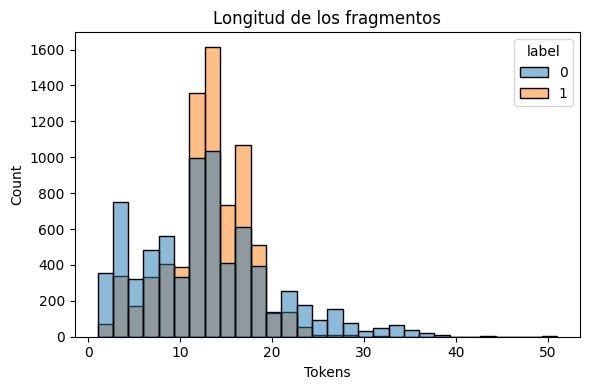

In [ ]:
fig, axes = plt.subplots(1, 1, figsize = (6, 4))
sns.histplot(data = train, x = "token_count", hue = "label", bins = 30, ax = axes)
axes.set_title("Longitud de los fragmentos")
axes.set_xlabel("Tokens")
plt.tight_layout()
plt.show()


Como se observa, los fragmentos de los True se centran mas entre 10 y 20 tokens, y aunque también es la zona mas grande para el False, se reparte de una forma un poco mas uniforme.

Para hacer esto primero eliminamos las *stopwords*, ya que estas palabras pueden añadir ruido y ser extremadamente comunes en ambos casos.

In [ ]:
STOPWORDS = {
    'the', 'and', 'a', 'of', 'to', 'in', 'is', 'was', 'with', 'for', 'on', 'as', 'by',
    'at', 'an', 'be', 'or', 'are', 'from', 'this', 'that', 'it', 'he', 'she', 'his', 'her',
    'patient', 'patients', 'with', 'had', 'has', 'have', 'were', 'not', 'but', 'who', 'been'
}

def get_most_common_words(df, label_val, top_n=15):
    texts = df[df['label'] == label_val]['text'].astype(str)

    full_text = " ".join(texts).lower()
    full_text = full_text.translate(str.maketrans('', '', string.punctuation))

    words = [
        word for word in full_text.split()
        if word not in STOPWORDS and not word.isdigit() and len(word) > 2
    ]

    return Counter(words).most_common(top_n)

for label_code, label_name in ID_TO_LABEL.items():
    print(f"=== Palabras más comunes para {label_name} ===")
    common_words = get_most_common_words(train, label_code, top_n=15)
    for word, count in common_words:
        print(f"{word}: {count}")
    print("\n" + "="*40 + "\n")

=== Palabras más comunes para NO_BHC ===
blood: 428
daily: 401
you: 324
your: 295
tablet: 281
pain: 237
left: 188
sig: 160
right: 154
normal: 153
one: 142
day: 127
bid: 120
plt: 110
status: 83


=== Palabras más comunes para BHC ===
pain: 299
given: 264
home: 261
continued: 254
discharge: 245
admission: 189
which: 184
started: 169
stable: 160
will: 158
outpatient: 155
likely: 149
daily: 145
after: 143
also: 141




En general, las palabras mas comunes para ambos difieren, entre las mas comunes mostradas, únicamente "pain" y "daily" se repiten en ambos bandos, esto puede dar un indicio de que el modelo si sea capaz de encontrar una verdadera diferencia entre ambas etiquetas durante el entrenamiento.

**Ejemplos de fragmentos marcados con label 1 (BHC)**

In [ ]:
for fragment in np.random.choice(train[train.label == 1]["text"].to_numpy(), size = 5):
  print(fragment)

# Type 2 diabetes: Held patient's home oral agents (Pioglitazone
another fever.  Transfer order were written for the step down
#CONTACT: Patient, Health Care Proxy - Daughter ___
#) Protective Factors:
[ ] Start methenamine hippurate 1 gram oral BID and Cefpodoxime


**Ejemplos de fragmentos marcados con label 0 (NO_BHC)**

In [ ]:
for fragment in np.random.choice(train[train.label == 0]["text"].to_numpy(), size = 5):
  print(fragment)

colonoscopy.
You were admitted into the hosptial for evaluation of your fall.
vancomycin.
from obstructive uropathy.  No calculus.  There is an enlarged
in a senior living facility in ___.


# PREPARACIÓN PARA EL ENTRENAMIENTO

Se convierten los fragmentos a Dataset. El modelo recibe los tokens del campo text y la etiqueta numérica. El resto de columnas se conserva aparte para evaluar y guardar resultados.


In [ ]:
def tokenize_batch(batch: dict, tokenizer: PreTrainedTokenizerBase) -> dict:
    """
    Convierte un lote de textos en las entradas de GPT-2.
    """
    return tokenizer(batch["text"], truncation = False, add_special_tokens = False)

def prepare_dataset(frame: pd.DataFrame, tokenizer: PreTrainedTokenizerBase) -> Dataset:
    """
    Prepara el conjunto que recibe Trainer.
    """
    dataset = Dataset.from_dict({"text": frame["text"].tolist(), "labels": frame["label"].astype(int).tolist()})
    return dataset.map(
        tokenize_batch, batched = True, fn_kwargs = {"tokenizer": tokenizer}, remove_columns = ["text"],
    )

In [ ]:
train_bhc = train[train["label"] == 1]
train_no_bhc = train[train["label"] == 0]

train_no_bhc_balanced = train_no_bhc.sample(n=len(train_bhc), random_state=SEED)

train_balanced = pd.concat([train_bhc, train_no_bhc_balanced]).sample(frac=1, random_state=SEED).reset_index(drop=True)

train = train_balanced

print(train["label"].value_counts().rename(index=ID_TO_LABEL))
train_dataset = prepare_dataset(train, tokenizer)

label
BHC       7356
NO_BHC    7356
Name: count, dtype: int64


Map:   0%|          | 0/14712 [00:00<?, ? examples/s]

In [ ]:
train_dataset = prepare_dataset(train, tokenizer)
val_dataset = prepare_dataset(val, tokenizer)
test_dataset = prepare_dataset(test, tokenizer)

display(pd.DataFrame({
    "particion": ["train", "validation", "test"],
    "fragmentos": [len(train_dataset), len(val_dataset), len(test_dataset)],
    "admisiones": [train["hadm_id"].nunique(), val["hadm_id"].nunique(), test["hadm_id"].nunique()],
}))


Map:   0%|          | 0/14712 [00:00<?, ? examples/s]

Map:   0%|          | 0/8556 [00:00<?, ? examples/s]

Map:   0%|          | 0/8372 [00:00<?, ? examples/s]

,particion,fragmentos,admisiones
0,train,14712,184
1,validation,8556,39
2,test,8372,40


# DEFINICIÓN DE LAS MÉTRICAS

Para comparar el learning-rate se utiliza macro-F1, y se reporta también precisión, recall y F1 para cada clase.

In [ ]:
def calculate_metrics(labels: np.ndarray, predictions: np.ndarray) -> dict:
    """
    Calcula las métricas de la clasificación binaria.
    """
    labels = np.asarray(labels, dtype = int)
    predictions = np.asarray(predictions, dtype = int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, labels = [0, 1], zero_division = 0,
    )
    return {
        "macro_f1": float(f1_score(labels, predictions, labels = [0, 1], average = "macro", zero_division = 0)),
        "bhc_precision": float(precision[1]), "bhc_recall": float(recall[1]),
        "bhc_f1": float(f1[1]), "n_fragments": int(len(labels)),
    }


def compute_metrics(prediction: EvalPrediction) -> dict:
    """
    Adapta la salida de Trainer al cálculo de métricas.
    """
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted_labels = np.argmax(logits, axis = -1)
    return calculate_metrics(prediction.label_ids, predicted_labels)


def get_bhc_probabilities(logits: np.ndarray | tuple) -> np.ndarray:
    """
    Convierte las puntuaciones del modelo a probabilidades de BHC.
    """
    if isinstance(logits, tuple):
        logits = logits[0]
    logits = np.asarray(logits, dtype = np.float64)
    if logits.ndim != 2 or logits.shape[1] != len(ID_TO_LABEL) or not np.isfinite(logits).all():
        raise ValueError("Los logits deben tener dos clases y valores finitos. Revisa los registros del entrenamiento.")
    exponents = np.exp(logits - logits.max(axis = -1, keepdims = True))
    return (exponents / exponents.sum(axis = -1, keepdims = True))[:, 1]


# DEFINICIÓN DEL MODELO

Se carga GPT2ForSequenceClassification con dos salidas, BHC y NO_BHC y se hace un padding


In [ ]:
def create_classifier(tokenizer: PreTrainedTokenizerBase) -> GPT2ForSequenceClassification:
    """
    Carga GPT-2 y prepara un clasificador nuevo para cada experimento.
    """
    set_seed(SEED)
    model = GPT2ForSequenceClassification.from_pretrained(
        MODEL_ID, num_labels = len(ID_TO_LABEL), id2label = ID_TO_LABEL, label2id = LABEL_TO_ID,
    )
    model.resize_token_embeddings(len(tokenizer), mean_resizing = False)
    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.use_cache = False
    model.config.problem_type = "single_label_classification"
    if MAX_LENGTH > model.config.max_position_embeddings:
        raise ValueError("MAX_LENGTH supera el contexto de GPT-2.")
    return model


def train_classifier(
    train_data: Dataset,
    validation_data: Dataset,
    tokenizer: PreTrainedTokenizerBase,
    learning_rate: float,
    output_route: str,
    weight_decay: float = WEIGHT_DECAY,
    num_train_epochs: int = NUM_TRAIN_EPOCHS,
    batch_size: int = BATCH_SIZE,
    warmup_ratio: float = WARMUP_RATIO,
) -> Trainer:
    """
    Entrena el clasificador con la configuración indicada.
    """

    training_args = TrainingArguments(
        output_dir = output_route,
        num_train_epochs = num_train_epochs,
        learning_rate = learning_rate,
        weight_decay = weight_decay,
        per_device_train_batch_size = batch_size,
        per_device_eval_batch_size = batch_size,
        eval_strategy = "epoch",
        save_strategy = "epoch",
        save_total_limit = 1,
        load_best_model_at_end = True,
        metric_for_best_model = "macro_f1",
        greater_is_better = True,
        warmup_steps = 0,
        optim = OPTIMIZER,
        lr_scheduler_type = LR_SCHEDULER_TYPE,
        max_grad_norm = MAX_GRAD_NORM,
        logging_steps = LOGGING_STEPS,
        report_to = "none",
        fp16 = torch.cuda.is_available(),
        bf16 = False,
        seed = SEED,
        data_seed = SEED,
        dataloader_num_workers = 0,
        gradient_accumulation_steps = 1,
        dataloader_drop_last = False,
    )

    model = create_classifier(tokenizer)

    trainer = Trainer(
        model = model,
        args = training_args,
        train_dataset = train_data,
        eval_dataset = validation_data,
        processing_class = tokenizer,
        data_collator = DataCollatorWithPadding(tokenizer = tokenizer),
        compute_metrics = compute_metrics,
    )

    steps_per_epoch = len(trainer.get_train_dataloader())
    total_steps = int(np.ceil(steps_per_epoch * num_train_epochs))

    trainer.args.warmup_steps = int(np.ceil(total_steps * warmup_ratio))

    trainer.train()

    return trainer


# BÚSQUEDA DE HIPERPARÁMETROS

Se toma una muestra fija de admisiones del entrenamiento y se comparan las diferentes corridas realizadas con una grilla de hiperparametros de 72 combinaciones.

In [ ]:
required_parameters = {
    "learning_rate",
    "weight_decay",
    "num_train_epochs",
    "batch_size",
    "warmup_ratio",
}

search_ids = np.random.default_rng(SEED).choice(
    train["hadm_id"].unique(),
    size = min(N_SEARCH_ADMISSIONS, train["hadm_id"].nunique()),
    replace = False,
)

train_sample = train.loc[
    train["hadm_id"].isin(search_ids)
].reset_index(drop = True)

search_dataset = prepare_dataset(train_sample, tokenizer)

parameter_combinations = list(product(
    LEARNING_RATES,
    WEIGHT_DECAYS,
    TRAIN_EPOCHS,
    BATCH_SIZES,
    WARMUP_RATIOS,
))

grid_columns = [
    "learning_rate",
    "weight_decay",
    "num_train_epochs",
    "batch_size",
    "warmup_ratio",
]

grid = pd.DataFrame(parameter_combinations, columns = grid_columns)
grid.insert(0, "experiment_id", np.arange(1, len(grid) + 1))

grid_path = output_path / "grilla"
grid_path.mkdir(parents = True, exist_ok = True)

grid_results_path = grid_path / "Experimentos.csv"

search_temp_path = Path(SEARCH_TEMP_ROUTE)
search_temp_path.mkdir(parents = True, exist_ok = True)

grid_settings = {
    "model_id": MODEL_ID,
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "optimizer": OPTIMIZER,
    "scheduler": LR_SCHEDULER_TYPE,
    "max_grad_norm": MAX_GRAD_NORM,
    "labels": ID_TO_LABEL,
    "tokenizer": tokenizer.name_or_path,
    "vocabulary_size": len(tokenizer),
    "pad_token_id": tokenizer.pad_token_id,
    "transformers_version": transformers.__version__,
    "torch_version": torch.__version__,
    "gpu_count": torch.cuda.device_count(),
    "grid": grid[grid_columns].to_dict("records"),
}

search_signature = sha256((
    json.dumps(grid_settings, sort_keys = True)
    + train_sample[["fragment_id", "text", "label"]].to_json(orient = "records")
    + val[["fragment_id", "text", "label"]].to_json(orient = "records")
).encode("utf-8")).hexdigest()

if grid_results_path.exists():
    saved_experiments = pd.read_csv(grid_results_path)

    if (
        "search_signature" not in saved_experiments
        or not saved_experiments["search_signature"].eq(search_signature).all()
    ):
        backup_path = grid_path / f"Experimentos_backup_{int(perf_counter())}.csv"
        grid_results_path.rename(backup_path)
        experiments = []
    else:
        experiments = saved_experiments.to_dict("records")
else:
    experiments = []

grid.to_csv(grid_path / "GrillaCompleta.csv", index = False)

with (grid_path / "Configuracion.json").open("w", encoding = "utf-8") as file:
    json.dump(
        {"signature": search_signature, "settings": grid_settings},
        file,
        ensure_ascii = False,
        indent = 2,
    )

print(f'Se tiene un total de {grid.shape[0]} combinaciones de hiperparametros.')

Map:   0%|          | 0/6251 [00:00<?, ? examples/s]

Se tiene un total de 72 combinaciones de hiperparametros.


In [ ]:
completed_ids = {
    int(row["experiment_id"])
    for row in experiments
    if row["status"] == "completed"
}

pending = [
    row
    for row in grid.to_dict("records")
    if row["experiment_id"] not in completed_ids
]

print("Corridas completadas anteriormente:", len(completed_ids))
print("Corridas que se ejecutarán en esta sesión:", len(pending))

for parameters in pending:
    experiment_id = int(parameters["experiment_id"])

    trial_params = {
        "learning_rate": float(parameters["learning_rate"]),
        "weight_decay": float(parameters["weight_decay"]),
        "num_train_epochs": int(parameters["num_train_epochs"]),
        "batch_size": int(parameters["batch_size"]),
        "warmup_ratio": float(parameters["warmup_ratio"]),
    }

    record = {
        "experiment_id": experiment_id,
        "search_signature": search_signature,
        **trial_params,
    }

    record["gpu"] = torch.cuda.get_device_name(0)

    trainer = None
    started = perf_counter()

    print(f"Experimento {experiment_id}/{len(grid)}:", trial_params)

    try:
        with TemporaryDirectory(
            prefix = f"experimento_{experiment_id}_",
            dir = str(search_temp_path),
        ) as trial_path:

            trainer = train_classifier(
                search_dataset,
                val_dataset,
                tokenizer,
                output_route = trial_path,
                **trial_params,
            )

            validation_history = [
                row
                for row in trainer.state.log_history
                if "eval_macro_f1" in row
            ]

            best_epoch_index = int(np.argmax([
                row["eval_macro_f1"]
                for row in validation_history
            ]))

            metrics = trainer.evaluate()

            if not all(
                np.isfinite(metrics[key])
                for key in ["eval_macro_f1", "eval_bhc_f1", "eval_loss"]
            ):
                raise FloatingPointError(
                    "La corrida produjo métricas no finitas."
                )

            record.update({
                "status": "completed",
                "best_epoch": float(
                    validation_history[best_epoch_index]["epoch"]
                ),
                "validation_macro_f1": float(metrics["eval_macro_f1"]),
                "validation_bhc_f1": float(metrics["eval_bhc_f1"]),
                "validation_loss": float(metrics["eval_loss"]),
                "error": "",
            })

    except (torch.cuda.OutOfMemoryError, FloatingPointError) as error:
        record.update({
            "status": "failed",
            "error": str(error)[:1000],
        })

        print("Corrida no completada:", type(error).__name__)

    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()

    record.update({
        "seconds": perf_counter() - started,
        "train_admissions": int(train_sample["hadm_id"].nunique()),
        "train_fragments": len(train_sample),
    })

    experiments.append(record)

    temporary_results_path = grid_path / "Experimentos.tmp.csv"

    pd.DataFrame(experiments).drop_duplicates(
        "experiment_id",
        keep = "last",
    ).to_csv(temporary_results_path, index = False)

    temporary_results_path.replace(grid_results_path)

attempts_df = pd.DataFrame(experiments).drop_duplicates(
    "experiment_id",
    keep = "last",
)

if attempts_df.empty or not attempts_df["status"].eq("completed").any():
    raise RuntimeError(
        "No hay corridas completadas para seleccionar un modelo. "
        "Revisa la tabla de intentos."
    )

experiments_df = attempts_df.loc[
    attempts_df["status"].eq("completed")
].sort_values(
    ["validation_macro_f1", "validation_bhc_f1"],
    ascending = False,
    kind = "mergesort",
).reset_index(drop = True)

best_experiment = experiments_df.iloc[0]

best_params = {
    "learning_rate": float(best_experiment["learning_rate"]),
    "weight_decay": float(best_experiment["weight_decay"]),
    "num_train_epochs": int(best_experiment["num_train_epochs"]),
    "batch_size": int(best_experiment["batch_size"]),
    "warmup_ratio": float(best_experiment["warmup_ratio"]),
}

best_learning_rate = best_params["learning_rate"]

display(experiments_df)
print("Mejores hiperparámetros:", best_params)

print(
    f"Comparación: {len(experiments_df)} corridas completadas "
    f"de {len(grid)} combinaciones; {len(attempts_df)} intentadas."
)

if len(experiments_df) < len(grid):
    print(
        "Búsqueda parcial: el ganador corresponde únicamente "
        "a las corridas completadas hasta ahora."
    )

Corridas completadas anteriormente: 0
Corridas que se ejecutarán en esta sesión: 72
Experimento 1/72: {'learning_rate': 0.0001, 'weight_decay': 0.001, 'num_train_epochs': 1, 'batch_size': 4, 'warmup_ratio': 0.03}


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: openai-community/gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Bhc Precision,Bhc Recall,Bhc F1,N Fragments
1,0.248864,0.465793,0.781224,0.549318,0.858623,0.669995,8556


... (498 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Macro F1,Bhc Precision,Bhc Recall,Bhc F1,N Fragments
0.308355,0.432911,3,0.737427,0.494753,0.775746,0.604177,8556


,experiment_id,search_signature,learning_rate,weight_decay,num_train_epochs,batch_size,warmup_ratio,gpu,status,best_epoch,validation_macro_f1,validation_bhc_f1,validation_loss,error,seconds,train_admissions,train_fragments
0,7,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0001,0.001,3,16,0.03,Tesla T4,completed,3.0,0.809404,0.705062,0.426147,,171.307899,80,6251
1,8,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0001,0.001,3,16,0.10,Tesla T4,completed,3.0,0.808729,0.703056,0.414129,,193.292773,80,6251
2,24,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0001,0.100,3,16,0.10,Tesla T4,completed,3.0,0.807713,0.700738,0.418659,,192.945432,80,6251
3,15,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0001,0.010,3,16,0.03,Tesla T4,completed,3.0,0.806319,0.700129,0.424325,,330.374988,80,6251
4,23,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0001,0.100,3,16,0.03,Tesla T4,completed,3.0,0.804755,0.697457,0.426222,,190.791165,80,6251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,56,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0100,0.001,3,16,0.10,Tesla T4,completed,1.0,0.679499,0.546218,0.587513,,189.459877,80,6251
57,69,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0100,0.100,3,4,0.03,Tesla T4,completed,3.0,0.562012,0.397075,0.608416,,661.828874,80,6251
58,53,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0100,0.001,3,4,0.03,Tesla T4,completed,1.0,0.446965,0.000000,0.555727,,496.355378,80,6251
59,68,0bc3947c6d49d841149c5f39239bb65fea1989d8f7a9b6...,0.0100,0.100,1,16,0.10,Tesla T4,completed,1.0,0.446965,0.000000,0.567929,,73.996896,80,6251


Mejores hiperparámetros: {'learning_rate': 0.0001, 'weight_decay': 0.001, 'num_train_epochs': 3, 'batch_size': 16, 'warmup_ratio': 0.03}
Comparación: 61 corridas completadas de 72 combinaciones; 72 intentadas.
Búsqueda parcial: el ganador corresponde únicamente a las corridas completadas hasta ahora.


Durante el entrenamiento de 72 combinaciones de hiperparametros, hubo 11 corridas fallidas, fueron descartadas por resultados con números no finitos, por lo tanto, el ganador como el **mejor modelo** se selecciona basandose en los 61 modelos restantes.

# ENTRENAMIENTO DEL MEJOR MODELO

Se vuelve a cargar la base y se entrena con todos los fragmentos de entrenamiento de la muestra seleccionada, utilizando los hiperparametros ganadores.

Para hacer esto primero se toman los 600 admisiones mas, aumentando la cohorte hasta un máximo de 900, aunque se va a reducir durante la selección de aquellos que tienen el BHC facilmente extraible.

In [ ]:
pending_candidates = np.setdiff1d(id_all, selected_ids)
new_selected_ids = np.asarray(
    random.choice(pending_candidates, size = min(600, pending_candidates.size), replace = False),
    dtype = np.int64
)
total_selected_ids = np.unique(np.concatenate([selected_ids, new_selected_ids]))

print(f"Admisiones previas: {len(selected_ids)}")
print(f"Nuevas admisiones agregadas: {len(new_selected_ids)}")
print(f"Total de admisiones combinadas: {len(total_selected_ids)}")

query_extendida = f"""
SELECT note_id, subject_id, hadm_id, note_seq, text
FROM `{PROJECT}.{DATASET_N}.discharge`
WHERE hadm_id IN UNNEST(@ids)
"""

job_config = bigquery.QueryJobConfig(
    query_parameters=[
        bigquery.ArrayQueryParameter("ids", "INT64", total_selected_ids.tolist())
    ]
)

notes_selected = client.query(query_extendida, job_config=job_config).to_dataframe(create_bqstorage_client=False)
notes_selected = notes_selected.sort_values("hadm_id").reset_index(drop=True)
print(f"Total de notas cargadas (ordenadas): {len(notes_selected)}")

print("Buscando límites y validez de la sección BHC...")
annotations = pd.DataFrame([find_bhc_span(text) for text in notes_selected["text"]])
for col in annotations.columns:
    if col in notes_selected.columns:
        notes_selected = notes_selected.drop(columns=[col])
notes_selected = pd.concat([notes_selected, annotations], axis = 1)

print("Distribución del estado de la sección BHC:")
display(notes_selected["annotation_status"].value_counts().to_frame())

valid_notes = notes_selected[notes_selected["annotation_status"] == "rule_valid"].copy()

splitter = GroupShuffleSplit(n_splits = 1, test_size = HOLDOUT_SIZE, random_state = SEED)
train_indices, holdout_indices = next(splitter.split(valid_notes, groups = valid_notes["subject_id"]))
holdout = valid_notes.iloc[holdout_indices]

splitter_holdout = GroupShuffleSplit(n_splits = 1, test_size = TEST_SIZE_IN_HOLDOUT, random_state = SEED)
validation_indices, test_indices = next(splitter_holdout.split(holdout, groups = holdout["subject_id"]))

notes_selected["split"] = ""
notes_selected.loc[valid_notes.index[train_indices], "split"] = "train"
notes_selected.loc[holdout.index[validation_indices], "split"] = "validation"
notes_selected.loc[holdout.index[test_indices], "split"] = "test"

train_patients = set(notes_selected.loc[notes_selected["split"].eq("train"), "subject_id"])
validation_patients = set(notes_selected.loc[notes_selected["split"].eq("validation"), "subject_id"])
test_patients = set(notes_selected.loc[notes_selected["split"].eq("test"), "subject_id"])

if train_patients & validation_patients or train_patients & test_patients or validation_patients & test_patients:
    raise ValueError("¡Error! Hay filtración de pacientes entre particiones de datos.")

print("\nDistribución de las particiones creadas:")
display(notes_selected.groupby("split").agg(notas = ("note_id", "size"), pacientes = ("subject_id", "nunique")))

print("\nExtrayendo y construyendo fragmentos tokenizados...")
all_fragments = pd.DataFrame([
    fragment
    for note in notes_selected.to_dict("records")
    for fragment in make_fragments(note, tokenizer)
])

labeled_fragments = all_fragments.dropna(subset = ["label"]).copy()
labeled_fragments["label"] = labeled_fragments["label"].astype(int)

train = labeled_fragments.loc[labeled_fragments["split"].eq("train")].reset_index(drop = True)
val = labeled_fragments.loc[labeled_fragments["split"].eq("validation")].reset_index(drop = True)
test = labeled_fragments.loc[labeled_fragments["split"].eq("test")].reset_index(drop = True)

print("\nAplicando balanceo de clases por submuestreo en 'train'...")
train_bhc = train[train["label"] == 1]
train_no_bhc = train[train["label"] == 0]

train_no_bhc_balanced = train_no_bhc.sample(n=len(train_bhc), random_state=SEED)
train_balanced = pd.concat([train_bhc, train_no_bhc_balanced]).sample(frac=1, random_state=SEED).reset_index(drop=True)
train = train_balanced

print("Distribución final de clases balanceadas en train:")
print(train["label"].value_counts().rename(index=ID_TO_LABEL))

train_dataset = prepare_dataset(train, tokenizer)
val_dataset = prepare_dataset(val, tokenizer)
test_dataset = prepare_dataset(test, tokenizer)

print("\nDatasets finales listos para el entrenamiento:")
display(pd.DataFrame({
    "particion": ["train", "validation", "test"],
    "fragmentos": [len(train_dataset), len(val_dataset), len(test_dataset)],
    "admisiones": [train["hadm_id"].nunique(), val["hadm_id"].nunique(), test["hadm_id"].nunique()],
}))

Admisiones previas: 300
Nuevas admisiones agregadas: 600
Total de admisiones combinadas: 900
Total de notas cargadas (ordenadas): 900
Buscando límites y validez de la sección BHC...
Distribución del estado de la sección BHC:


,count
annotation_status,
rule_valid,796
missing,94
ambiguous,10



Distribución de las particiones creadas:


,notas,pacientes
split,,
,104,103
test,118,118
train,558,550
validation,120,118



Extrayendo y construyendo fragmentos tokenizados...

Aplicando balanceo de clases por submuestreo en 'train'...
Distribución final de clases balanceadas en train:
label
BHC       24236
NO_BHC    24236
Name: count, dtype: int64


Map:   0%|          | 0/48472 [00:00<?, ? examples/s]

Map:   0%|          | 0/24900 [00:00<?, ? examples/s]

Map:   0%|          | 0/25018 [00:00<?, ? examples/s]


Datasets finales listos para el entrenamiento:


,particion,fragmentos,admisiones
0,train,48472,558
1,validation,24900,120
2,test,25018,118


In [ ]:
trainer = train_classifier(
    train_dataset,
    val_dataset,
    tokenizer,
    output_route = str(output_path / "entrenamiento_final"),
    **best_params,
)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: openai-community/gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Bhc Precision,Bhc Recall,Bhc F1,N Fragments
1,0.334780,0.293314,0.816240,0.597925,0.907812,0.720981,24900
2,0.263037,0.315075,0.823175,0.609955,0.910962,0.730672,24900
3,0.224878,0.366185,0.829359,0.624891,0.902562,0.738488,24900


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
train_csv_path = output_path / "DatasetEntrenamientoFinal.csv"
train.to_csv(train_csv_path, index = False)
print(f"Se ha guardado el CSV de entrenamiento en: {train_csv_path}")

train_hf_path = output_path / "dataset_entrenamiento_hf"
train_dataset.save_to_disk(str(train_hf_path))
print(f"Se ha guardado el Dataset de HuggingFace de entrenamiento en: {train_hf_path}")

val_csv_path = output_path / "DatasetValidacionFinal.csv"
test_csv_path = output_path / "DatasetTestFinal.csv"
val.to_csv(val_csv_path, index = False)
test.to_csv(test_csv_path, index = False)
print(f"Se ha guardado el CSV de validación en: {val_csv_path}")
print(f"Se ha guardado el CSV de prueba en: {test_csv_path}")

val_hf_path = output_path / "dataset_validacion_hf"
test_hf_path = output_path / "dataset_test_hf"
val_dataset.save_to_disk(str(val_hf_path))
test_dataset.save_to_disk(str(test_hf_path))
print(f"Se ha guardado el Dataset de HuggingFace de validación en: {val_hf_path}")
print(f"Se ha guardado el Dataset de HuggingFace de prueba en: {test_hf_path}")

Se ha guardado el CSV de entrenamiento en: /content/drive/MyDrive/MIMIC/Clasificacion_Tarea/DatasetEntrenamientoFinal.csv


Saving the dataset (0/1 shards):   0%|          | 0/48472 [00:00<?, ? examples/s]

Se ha guardado el Dataset de HuggingFace de entrenamiento en: /content/drive/MyDrive/MIMIC/Clasificacion_Tarea/dataset_entrenamiento_hf
Se ha guardado el CSV de validación en: /content/drive/MyDrive/MIMIC/Clasificacion_Tarea/DatasetValidacionFinal.csv
Se ha guardado el CSV de prueba en: /content/drive/MyDrive/MIMIC/Clasificacion_Tarea/DatasetTestFinal.csv


Saving the dataset (0/1 shards):   0%|          | 0/24900 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/25018 [00:00<?, ? examples/s]

Se ha guardado el Dataset de HuggingFace de validación en: /content/drive/MyDrive/MIMIC/Clasificacion_Tarea/dataset_validacion_hf
Se ha guardado el Dataset de HuggingFace de prueba en: /content/drive/MyDrive/MIMIC/Clasificacion_Tarea/dataset_test_hf


# SELECCIÓN DEL UMBRAL

La probabilidad BHC se convierte a clase utilizando un umbral elegido en validación.
Se selecciona el mayor F1 de BHC. El umbral se fija antes de evaluar prueba.


In [ ]:
validation_output = trainer.predict(val_dataset)
validation_probabilities = get_bhc_probabilities(validation_output.predictions)
threshold_results = []
for threshold in THRESHOLDS:
    predicted_labels = (validation_probabilities >= threshold).astype(int)
    threshold_results.append({"threshold": float(threshold), **calculate_metrics(val["label"].to_numpy(), predicted_labels)})

threshold_results = pd.DataFrame(threshold_results).sort_values(
    ["bhc_f1", "bhc_precision", "threshold"], ascending = [False, False, False], kind = "mergesort",
).reset_index(drop = True)
best_threshold = float(threshold_results.iloc[0]["threshold"])
display(threshold_results)
print("Umbral seleccionado:", best_threshold)


,threshold,macro_f1,bhc_precision,bhc_recall,bhc_f1,n_fragments
0,0.85,0.847074,0.709974,0.810164,0.756767,24900
1,0.80,0.845608,0.689715,0.837883,0.756613,24900
2,0.75,0.844036,0.676921,0.854893,0.755568,24900
3,0.70,0.841545,0.663995,0.869803,0.753091,24900
4,0.90,0.846263,0.737065,0.768795,0.752595,24900
5,0.65,0.837782,0.650986,0.880512,0.748549,24900
6,0.60,0.835109,0.641484,0.889752,0.745491,24900
7,0.55,0.832173,0.632647,0.896892,0.741944,24900
8,0.50,0.829359,0.624891,0.902562,0.738488,24900
9,0.45,0.825688,0.615625,0.908442,0.733904,24900


Umbral seleccionado: 0.85


# EVALUACIÓN

Se evalúa el modelo final en prueba con el umbral ya fijado. Los resultados se separan
por referencias automáticas y manuales cuando ambas están disponibles.


In [ ]:
test_output = trainer.predict(test_dataset)
test_predictions = test.copy()
test_predictions["p_bhc"] = get_bhc_probabilities(test_output.predictions)
test_predictions["prediction"] = (test_predictions["p_bhc"] >= best_threshold).astype(int)

test_metrics = calculate_metrics(test_predictions["label"].to_numpy(), test_predictions["prediction"].to_numpy())
display(pd.DataFrame([test_metrics]))
print(classification_report(
    test_predictions["label"], test_predictions["prediction"],
    labels = [0, 1], target_names = [ID_TO_LABEL[0], ID_TO_LABEL[1]], zero_division = 0,
))

metrics_by_source = []
for source, frame in test_predictions.groupby("reference_source"):
    metrics_by_source.append({
        "reference_source": source,
        **calculate_metrics(frame["label"].to_numpy(), frame["prediction"].to_numpy()),
    })
metrics_by_source = pd.DataFrame(metrics_by_source)
display(metrics_by_source)
if not test_predictions["reference_source"].eq("manual").any():
    print("La evaluación actual utiliza etiquetas automáticas. Falta contrastarla con referencias revisadas.")


,macro_f1,bhc_precision,bhc_recall,bhc_f1,n_fragments
0,0.846512,0.723125,0.793152,0.756522,25018


              precision    recall  f1-score   support

      NO_BHC       0.95      0.93      0.94     20082
         BHC       0.72      0.79      0.76      4936

    accuracy                           0.90     25018
   macro avg       0.84      0.86      0.85     25018
weighted avg       0.90      0.90      0.90     25018



,reference_source,macro_f1,bhc_precision,bhc_recall,bhc_f1,n_fragments
0,rules,0.846512,0.723125,0.793152,0.756522,25018


La evaluación actual utiliza etiquetas automáticas. Falta contrastarla con referencias revisadas.


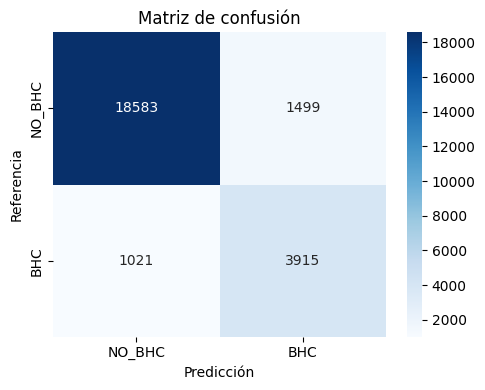

In [ ]:
confusion = confusion_matrix(test_predictions["label"], test_predictions["prediction"], labels = [0, 1])
plt.figure(figsize = (5, 4))
sns.heatmap(
    confusion, annot = True, fmt = "d", cmap = "Blues",
    xticklabels = ["NO_BHC", "BHC"], yticklabels = ["NO_BHC", "BHC"],
)
plt.xlabel("Predicción")
plt.ylabel("Referencia")
plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()


# GUARDADO DEL MODELO Y LOS RESULTADOS


In [ ]:
trainer.save_model(str(model_path))
tokenizer.save_pretrained(str(model_path))

notes_selected[["note_id", "subject_id", "hadm_id", "split", "annotation_status", "reference_source"]].to_csv(
    output_path / "Particiones.csv", index = False,
)
labeled_fragments.to_csv(output_path / "FragmentosEtiquetados.csv", index = False)
experiments_df.to_csv(output_path / "Experimentos.csv", index = False)
threshold_results.to_csv(output_path / "UmbralesValidacion.csv", index = False)
test_predictions.to_csv(output_path / "PrediccionesTest.csv", index = False)
metrics_by_source.to_csv(output_path / "MetricasPorReferencia.csv", index = False)

results = {
    "model_id": MODEL_ID,
    "seed": SEED,
    "best_hyperparameters": best_params,
    "learning_rate": best_params["learning_rate"],
    "weight_decay": best_params["weight_decay"],
    "num_train_epochs": best_params["num_train_epochs"],
    "batch_size": best_params["batch_size"],
    "warmup_ratio": best_params["warmup_ratio"],
    "threshold": best_threshold,
    "max_length": MAX_LENGTH,
    "max_fragment_tokens": MAX_FRAGMENT_TOKENS,
    "sample_admissions": len(notes_selected),
    "train_fragments": len(train),
    "validation_fragments": len(val),
    "test_fragments": len(test),
    "grid_combinations": len(grid),
    "grid_attempted": len(attempts_df),
    "grid_completed": len(experiments_df),
    "pad_token": PAD_TOKEN,
    "pad_token_id": tokenizer.pad_token_id,
    "test_metrics": test_metrics,
}

with (output_path / "Resultados.json").open("w", encoding = "utf-8") as file:
    json.dump(results, file, ensure_ascii = False, indent = 2)

del trainer, validation_output, test_output
gc.collect()
torch.cuda.empty_cache()


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

# CLASIFICACIÓN DE LAS NOTAS

Se recarga el modelo guardado y se clasifican todos los fragmentos de la muestra,
incluidos los que no tienen etiqueta de referencia. El resultado indica una probabilidad
y una clase por fragmento. Se marca una admisión como candidata cuando contiene al menos
`MIN_POSITIVE_FRAGMENTS` fragmentos positivos consecutivos. Es una regla inicial de selección,
no una garantía de que toda la sección esté correctamente identificada.


In [ ]:
def classify_fragments(
    fragments: pd.DataFrame,
    model: GPT2ForSequenceClassification,
    tokenizer: PreTrainedTokenizerBase,
    threshold: float = 0.5,
    batch_size: int = INFERENCE_BATCH_SIZE,
) -> pd.DataFrame:
    """
    Clasifica una tabla de fragmentos con el modelo ya entrenado.
    """
    if batch_size < 1 or not 0 <= threshold <= 1:
        raise ValueError("Revisa batch_size y threshold.")
    result = fragments.copy()
    probabilities = []
    model.eval()
    model_device = next(model.parameters()).device
    texts = result["text"].astype(str).tolist()
    for start in range(0, len(texts), batch_size):
        encoded = tokenizer(
            texts[start:start + batch_size], padding = True, truncation = False,
            add_special_tokens = False, return_tensors = "pt",
        )
        if encoded["input_ids"].shape[1] > MAX_LENGTH:
            raise ValueError("Hay fragmentos demasiado largos. Revisa su preparación.")
        encoded = {name: value.to(model_device) for name, value in encoded.items()}
        with torch.inference_mode():
            logits = model(**encoded).logits.float().cpu().numpy()
        probabilities.extend(get_bhc_probabilities(logits).tolist())
    result["p_bhc"] = probabilities
    result["prediction"] = (result["p_bhc"] >= threshold).astype(int)
    return result


def select_admissions(
    predictions: pd.DataFrame,
    notes: pd.DataFrame,
    min_positive_fragments: int = MIN_POSITIVE_FRAGMENTS,
) -> pd.DataFrame:
    """
    Agrupa las predicciones y marca las admisiones candidatas.
    """
    if min_positive_fragments < 1:
        raise ValueError("min_positive_fragments debe ser positivo.")
    groups = {note_id: frame for note_id, frame in predictions.groupby("note_id")}
    records = []
    for note in notes.to_dict("records"):
        frame = groups.get(note["note_id"])
        current, longest, positive_count, maximum = 0, 0, 0, 0.0
        if frame is not None:
            for predicted in frame.sort_values(["start", "end"]).to_dict("records"):
                current = current + 1 if predicted["prediction"] == 1 else 0
                longest = max(longest, current)
            positive_count = int(frame["prediction"].sum())
            maximum = float(frame["p_bhc"].max())
        records.append({
            "note_id": note["note_id"], "subject_id": note["subject_id"],
            "hadm_id": note["hadm_id"], "split": note["split"],
            "positive_fragments": positive_count, "longest_positive_run": longest,
            "max_probability": maximum, "candidate": longest >= min_positive_fragments,
        })
    return pd.DataFrame(records)


In [ ]:
with (output_path / "Resultados.json").open("r", encoding = "utf-8") as file:
    saved_results = json.load(file)
saved_threshold = float(saved_results["threshold"])

saved_tokenizer = AutoTokenizer.from_pretrained(str(model_path), use_fast = True)
saved_tokenizer.padding_side = "right"
saved_model = GPT2ForSequenceClassification.from_pretrained(str(model_path)).to(device)
saved_model.config.use_cache = False

if saved_model.config.pad_token_id != saved_tokenizer.pad_token_id:
    raise ValueError("El modelo y el tokenizador guardados tienen un PAD diferente.")
if saved_model.get_input_embeddings().num_embeddings != len(saved_tokenizer):
    raise ValueError("El vocabulario del modelo y el tokenizador no coinciden.")

fragment_predictions = classify_fragments(all_fragments, saved_model, saved_tokenizer, threshold = saved_threshold)
admission_predictions = select_admissions(fragment_predictions, notes_selected)
fragment_predictions.to_csv(output_path / "ClasificacionFragmentos.csv", index = False)
admission_predictions.to_csv(output_path / "ClasificacionAdmisiones.csv", index = False)

display(admission_predictions.groupby("split").agg(
    admisiones = ("note_id", "size"), candidatas = ("candidate", "sum"),
))
print("Resultados guardados en:", output_path)

del saved_model
gc.collect()
torch.cuda.empty_cache()


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

,admisiones,candidatas
split,,
,104,103
test,118,118
train,558,558
validation,120,120


Resultados guardados en: /content/drive/MyDrive/MIMIC/Clasificacion_Tarea


Se muestran aqui 6 ejemplos de inferencia, 3 para una clasificación de 1 (BHC) y 3 para clasificación de 0 (NO_BHC).

In [ ]:
ejemplos_bhc = fragment_predictions[fragment_predictions["prediction"] == 1].sample(n=3, random_state=SEED)
ejemplos_no_bhc = fragment_predictions[fragment_predictions["prediction"] == 0].sample(n=3, random_state=SEED)

print("EJEMPLOS CLASIFICADOS COMO BHC")
for idx, row in ejemplos_bhc.iterrows():
    print(f"Nota ID: {row['note_id']} | HADM ID: {row['hadm_id']} | Probabilidad: {row['p_bhc']:.4f}")
    print(f"Texto: \"{row['text']}\"")
    print("-" * 80)

print("EJEMPLOS CLASIFICADOS COMO NO_BHC")
for idx, row in ejemplos_no_bhc.iterrows():
    print(f"Nota ID: {row['note_id']} | HADM ID: {row['hadm_id']} | Probabilidad: {row['p_bhc']:.4f}")
    print(f"Texto: \"{row['text']}\"")
    print("-" * 80)

EJEMPLOS CLASIFICADOS COMO BHC
Nota ID: 16203068-DS-27 | HADM ID: 27108932 | Probabilidad: 0.9615
Texto: "nausea controlled with IV ondansetron 4mg x2.  Morphine with"
--------------------------------------------------------------------------------
Nota ID: 17698189-DS-11 | HADM ID: 27593606 | Probabilidad: 0.9979
Texto: "[ ] F/U MRCP in 6 months (ordered in OMR by ERCP team)"
--------------------------------------------------------------------------------
Nota ID: 14566733-DS-8 | HADM ID: 22322133 | Probabilidad: 0.9960
Texto: "orthostatic vital signs, although she denied being symptomatic"
--------------------------------------------------------------------------------
EJEMPLOS CLASIFICADOS COMO NO_BHC
Nota ID: 19258898-DS-22 | HADM ID: 24756914 | Probabilidad: 0.0044
Texto: "progressively worsened since that time.  Filled his"
--------------------------------------------------------------------------------
Nota ID: 10723086-DS-32 | HADM ID: 29401240 | Probabilidad: 0.0001
Texto: "-H

# Conclusiones


Durante el entrenamiento por busqueda de grilla se observó que en los casos donde aumentaba el error de entrenamiento, reducia el de validación y viceversa. Esto es compatible con un posible sobreajuste, que el modelo mejorara sobre los ejemplos de entrenamiento pero empeorara en la validación. Aún así, el macro-F1 de validación aumentaba, dificultando afirmar que el rendimiento general de la validación empeorara, especialmente porque la métrica F1 y el error miden cosas diferentes.

También se observó que ampliar la cohorte utilizada de 300 a 900 admisiones (Antes de reducción por no encontrar el BHC), permitió mejorar los resultados, con un modelo final con 0.76 de F1, 0.72 de precisión, y un 0.79 de recall en prueba. Disponer de mas ejemplos puede haber dado una mayor diversidad de hospitalizaciones, permitiendo con mas facilidad reconocer que fragmentos pertenecen al BHC.

Tampoco puede concluirse que la calidad de los datos no haya influido en el error, las etiquetas fueron construidas de forma automatica con detección de encabezados y limites, por lo que puede haber errores. Además, algunos fragmentos son muy cortos, ofreciendo poco contexto y dificultando la sección de origen, una evaluación posterior debería mantener un mínimo de tamaño (En tokens) para las particiones, para evitar que algunas secciones queden muy cortas. Teniendo en cuenta que la calidad puede haber influido, el tamaño de la cohorte puede no ser el único efecto en la mejora de las métricas.

La posible aplicación de encontrar el BHC entre un texto donde no se le pueda encontrar etiquetado o sea ambiguo queda a disposición de un modelo entrenado con una cohorte mas grande y una revisión mas profunda.